# Package dan Data

In [ ]:
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 8.4 MB/s eta 0:00:00


In [ ]:
!pip install xlsxwriter

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from scipy.stats import mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, f1_score

In [ ]:
# Set Angka Desimal
np.set_printoptions(precision=3, suppress=True)
pd.options.display.float_format = '{:.3f}'.format

In [ ]:
from google.colab import files
upload = files.upload() #upload file data

Saving Data.xlsx to Data.xlsx


In [ ]:
data = pd.read_excel("Data.xlsx")
df = pd.DataFrame(data)
df

,Wilayah,P1,P2,GK,JPM,PPK,AHH,RLS,IKK,PKKP,Label
0,Simeulue,2.620,0.600,576505,17.590,8106,65.775,9.890,108.800,10.080,0
1,Aceh Singkil,3.060,0.740,609322,24.840,9862,67.935,8.720,94.320,7.410,0
2,Aceh Selatan,1.570,0.310,528243,30.530,9190,65.020,8.920,98.650,10.440,0
3,Aceh Tenggara,1.640,0.350,496074,27.280,8876,68.825,10.100,93.430,9.440,0
4,Aceh Timur,2.040,0.460,557943,60.860,9889,69.230,8.480,95.470,8.710,0
...,...,...,...,...,...,...,...,...,...,...,...
509,Tolikara,2.790,0.420,675908,48.730,5653,66.560,3.690,288.590,38.640,1
510,Mamberamo Tengah,5.100,1.310,713489,20.200,4943,64.300,3.700,285.830,29.910,1
511,Yalimo,9.190,4.260,600536,21.440,5226,66.155,3.550,243.530,14.720,1
512,Yahukimo,4.670,0.930,718084,68.320,5747,66.575,4.350,169.540,46.360,1


# Data Preprocessing 1 (Pemeriksaan Data Duplikat dan Missing Value)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Wilayah,0
P1,0
P2,0
GK,0
JPM,0
PPK,0
AHH,0
RLS,0
IKK,0
PKKP,0


# Eksplorasi Data

In [ ]:
desc_stats = []

for col in df.columns:
    if col not in ['Wilayah', 'Label']:
        for label in sorted(df['Label'].unique()):
            data = df[df['Label'] == label][col]

            desc_stats.append({
                'Variabel': col,
                'Label': label,
                'Min': data.min(),
                'Max': data.max(),
                'Mean': data.mean(),
                'Median': data.median(),
                'SD': data.std()
            })

desc_df = pd.DataFrame(desc_stats).round(3)
desc_df


,Variabel,Label,Min,Max,Mean,Median,SD
0,P1,0,0.130,7.320,1.385,1.110,0.983
1,P1,1,1.010,12.810,4.631,4.455,2.396
2,P2,0,0.010,2.780,0.332,0.240,0.326
3,P2,1,0.200,5.350,1.463,1.225,0.980
4,GK,0,300991.000,1179015.000,556035.058,535613.000,125270.990
5,GK,1,381760.000,948843.000,616133.194,591286.000,147350.342
6,JPM,0,1.500,446.790,51.147,27.685,56.906
7,JPM,1,3.970,117.410,33.888,26.970,24.382
8,PPK,0,7242.000,25573.000,11975.024,11634.000,2509.005
9,PPK,1,4597.000,11198.000,7501.710,7361.500,1573.092


In [ ]:
label_dist = pd.DataFrame({
    'Frekuensi': df['Label'].value_counts(),
    'Proporsi': df['Label'].value_counts(normalize=True)
})

print(label_dist)

       Frekuensi  Proporsi
Label                     
0            452     0.879
1             62     0.121


In [ ]:
feature_names = {
    'P1': 'Indeks Kedalaman Kemiskinan (P1)',
    'P2': 'Indeks Keparahan Kemiskinan (P2)',
    'GK': 'Garis Kemiskinan (GK)',
    'JPM': 'Jumlah Penduduk Miskin (JPM)',
    'PPK': 'Pengeluaran Per Kapita (PPK)',
    'AHH': 'Angka Harapan Hidup (AHH)',
    'RLS': 'Rata-rata Lama Sekolah (RLS)',
    'IKK': 'Indeks Keparahan Kemiskinan (IKK)',
    'PKKP': 'Persentase Konsumsi Pangan Kurang (PKKP)'
}

In [ ]:
label_col = 'Label'
feature_cols = [col for col in df.columns if col not in ['Wilayah', label_col]]
feature_cols = feature_cols[:9]

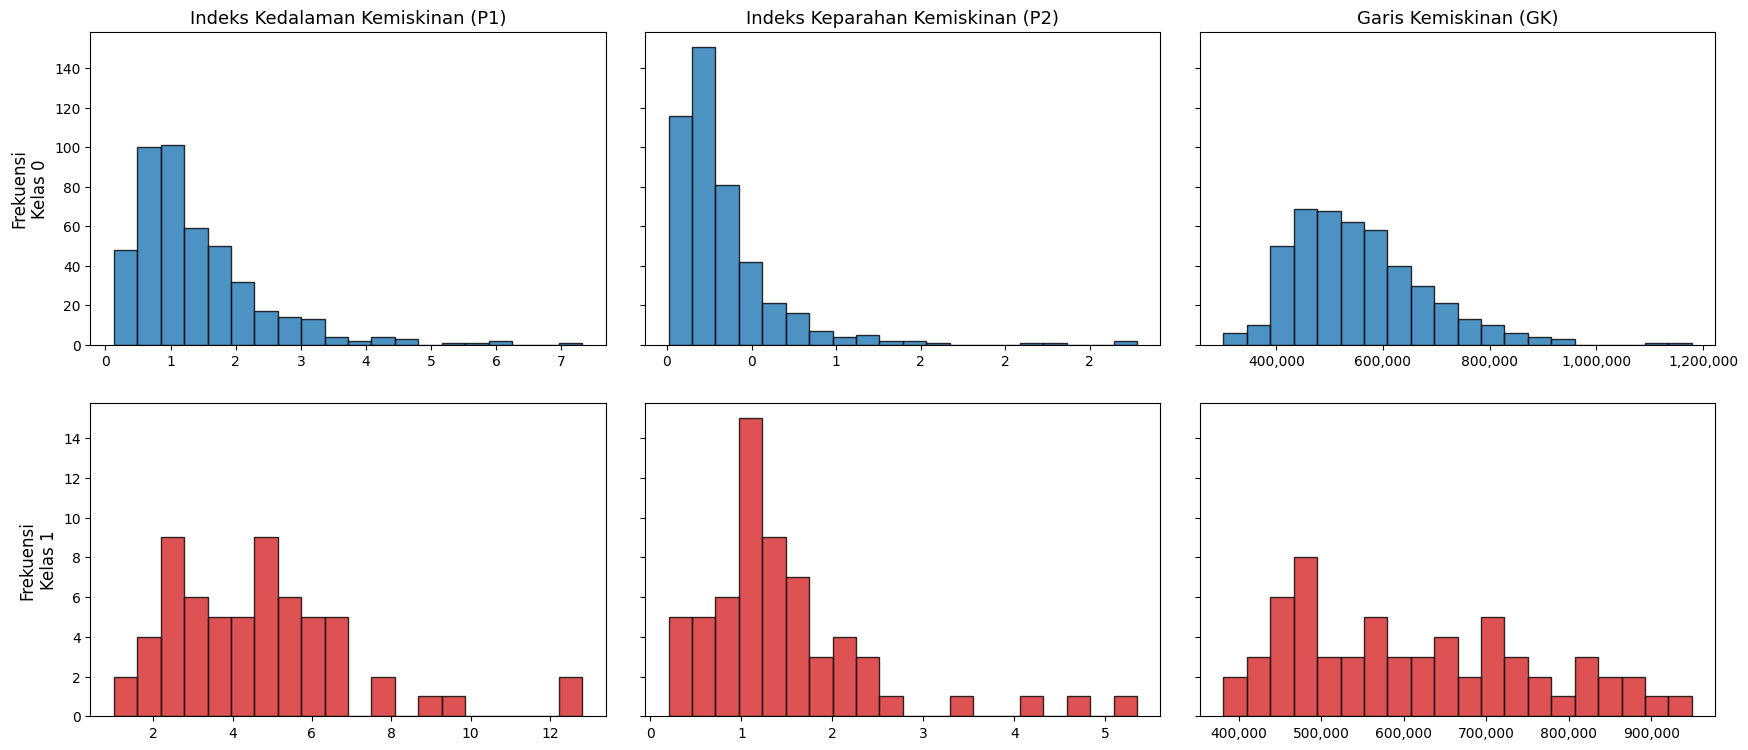

In [ ]:
# Histogram P1, P2, dan GK
vars_1 = feature_cols[0:3]

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey='row')

for i, col in enumerate(vars_1):

    # Kelas 0
    axes[0, i].hist(
        df[df[label_col] == 0][col],
        bins=20,
        color='tab:blue',
        alpha=0.8,
        edgecolor='black'
    )
    axes[0, i].set_title(feature_names[col], fontsize=13)
    if i == 0:
        axes[0, i].set_ylabel('Frekuensi\nKelas 0', fontsize=12)

    # Kelas 1
    axes[1, i].hist(
        df[df[label_col] == 1][col],
        bins=20,
        color='tab:red',
        alpha=0.8,
        edgecolor='black'
    )
    if i == 0:
        axes[1, i].set_ylabel('Frekuensi\nKelas 1', fontsize=12)
    axes[0, i].ticklabel_format(style='plain', axis='x')
    axes[1, i].ticklabel_format(style='plain', axis='x')
    axes[0, i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    axes[1, i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout(pad=2.5)
plt.show()

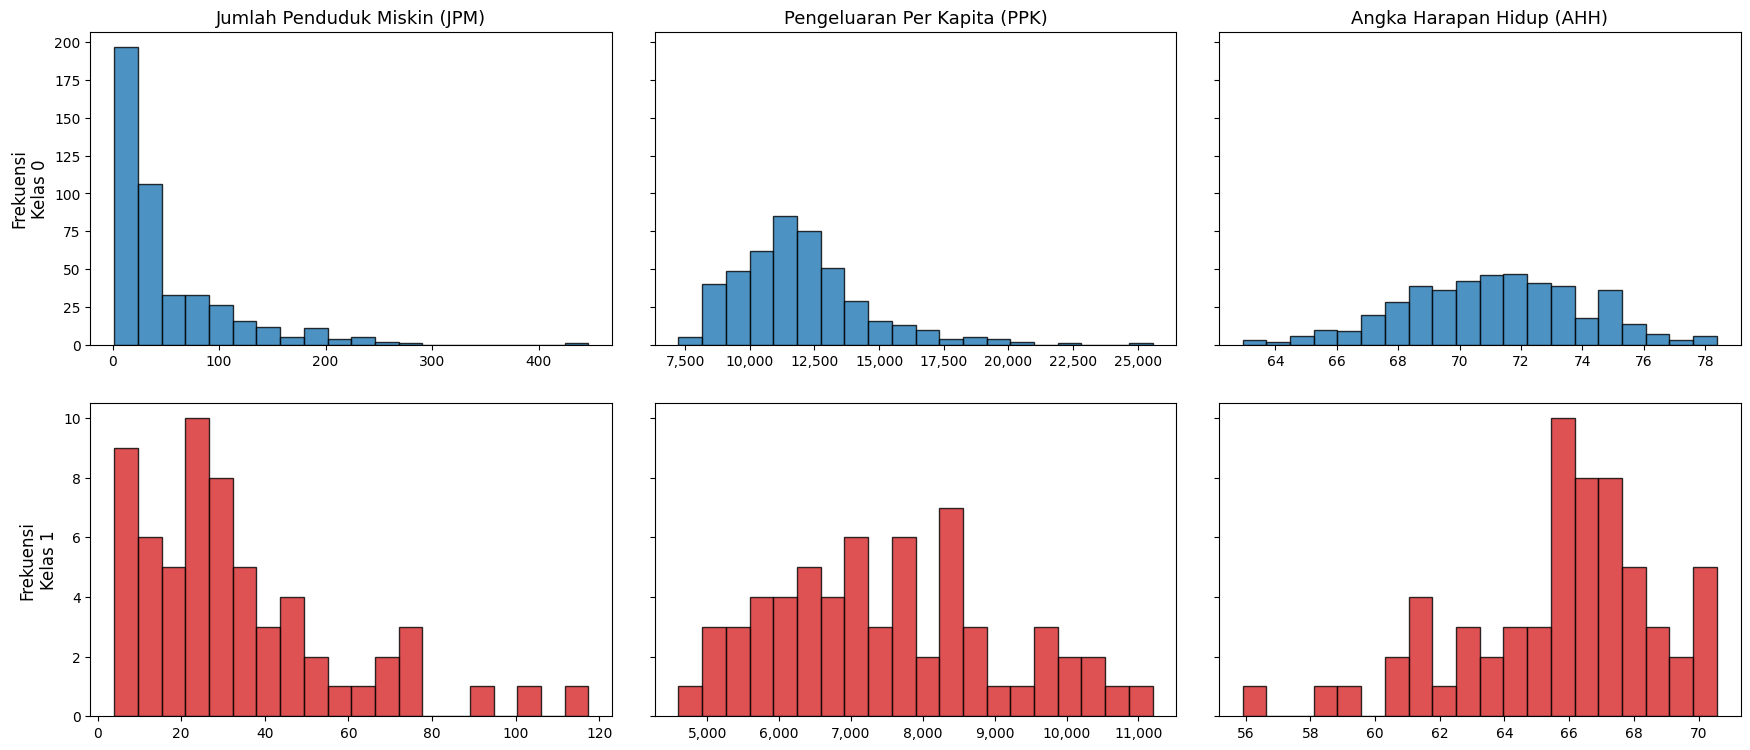

In [ ]:
vars_2 = feature_cols[3:6]

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey='row')

for i, col in enumerate(vars_2):

    # Kelas 0
    axes[0, i].hist(
        df[df[label_col] == 0][col],
        bins=20,
        color='tab:blue',
        alpha=0.8,
        edgecolor='black'
    )
    axes[0, i].set_title(feature_names[col], fontsize=13)
    if i == 0:
        axes[0, i].set_ylabel('Frekuensi\nKelas 0', fontsize=12)

    # Kelas 1
    axes[1, i].hist(
        df[df[label_col] == 1][col],
        bins=20,
        color='tab:red',
        alpha=0.8,
        edgecolor='black'
    )
    if i == 0:
        axes[1, i].set_ylabel('Frekuensi\nKelas 1', fontsize=12)

    axes[0, i].ticklabel_format(style='plain', axis='x')
    axes[1, i].ticklabel_format(style='plain', axis='x')
    axes[0, i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    axes[1, i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout(pad=2.5)
plt.show()

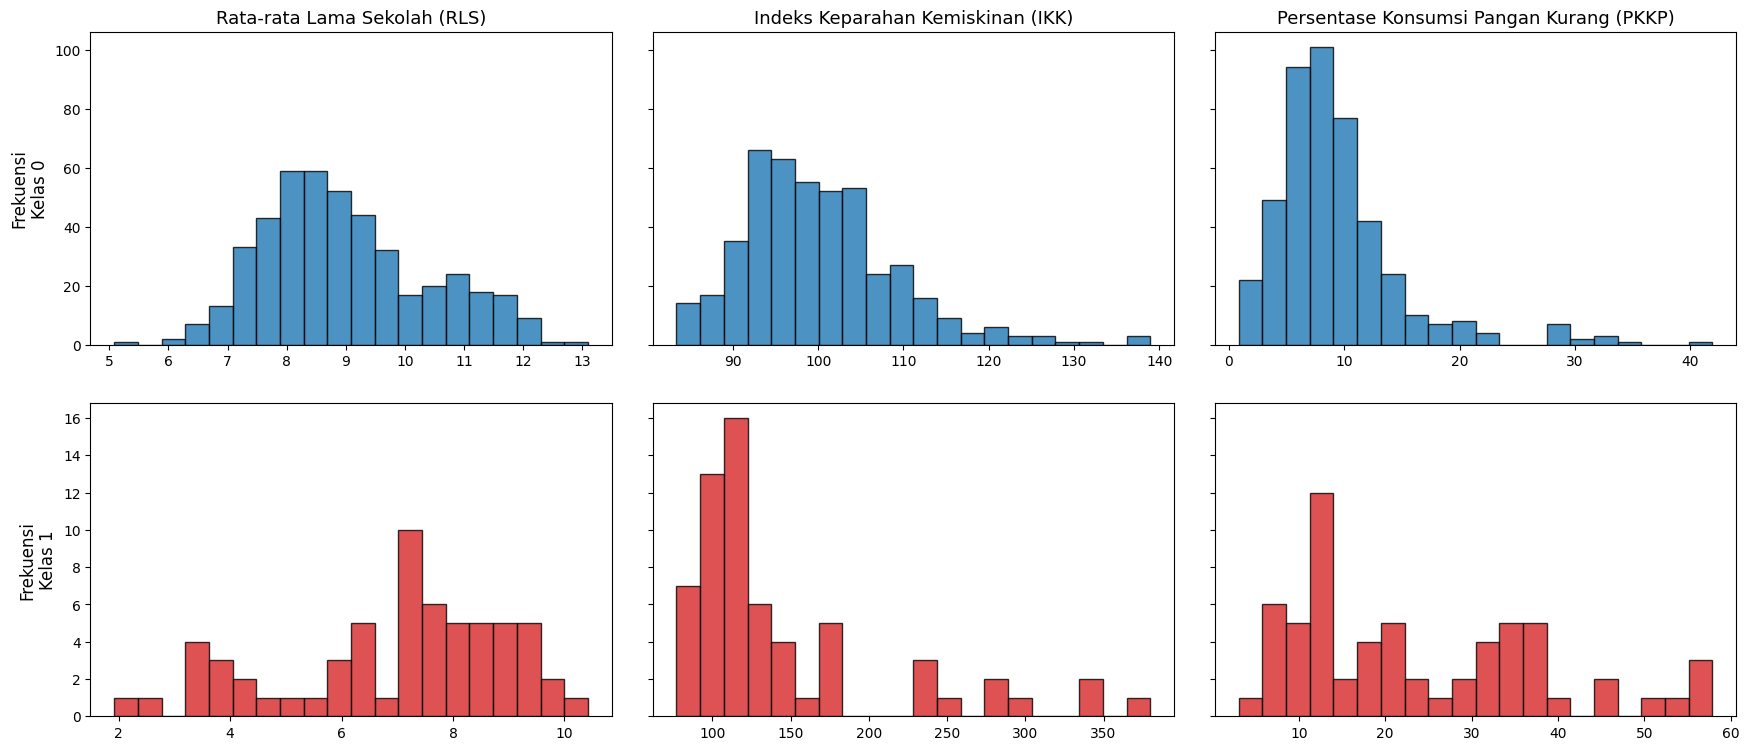

In [ ]:
vars_3 = feature_cols[6:9]

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey='row')

for i, col in enumerate(vars_3):

    # Kelas 0
    axes[0, i].hist(
        df[df[label_col] == 0][col],
        bins=20,
        color='tab:blue',
        alpha=0.8,
        edgecolor='black'
    )
    axes[0, i].set_title(feature_names[col], fontsize=13)
    if i == 0:
        axes[0, i].set_ylabel('Frekuensi\nKelas 0', fontsize=12)

    # Kelas 1
    axes[1, i].hist(
        df[df[label_col] == 1][col],
        bins=20,
        color='tab:red',
        alpha=0.8,
        edgecolor='black'
    )
    if i == 0:
        axes[1, i].set_ylabel('Frekuensi\nKelas 1', fontsize=12)

    axes[0, i].ticklabel_format(style='plain', axis='x')
    axes[1, i].ticklabel_format(style='plain', axis='x')
    axes[0, i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    axes[1, i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout(pad=2.5)
plt.show()


# Feature Selection

In [ ]:
# Mann-Whitney

results = []

for col in df.columns:
    if col not in ['Wilayah', label_col]:

        group0 = df[df[label_col] == 0][col]
        group1 = df[df[label_col] == 1][col]

        # Uji Mann-Whitney
        U1, p = mannwhitneyu(
            group0,
            group1,
            alternative='two-sided'
        )

        n1, n2 = len(group0), len(group1)

        # Statistik Uji U
        U2 = n1 * n2 - U1
        U = min(U1, U2)
        mu_U = n1 * n2 / 2
        sigma_U = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)

        # Statistik Z
        Z = (U - mu_U) / sigma_U

        results.append({
            'Variabel': col,
            'Median_Label_0': round(group0.median(), 3),
            'Median_Label_1': round(group1.median(), 3),
            'U_statistic': round(U, 3),
            'Z_statistic': round(Z, 3),
            'p_value': round(p, 4),
            'Keputusan': 'Signifikan' if p < 0.05 else 'Tidak signifikan'
        })

mw_results = pd.DataFrame(results).sort_values('p_value')
mw_results

,Variabel,Median_Label_0,Median_Label_1,U_statistic,Z_statistic,p_value,Keputusan
0,P1,1.110,4.455,1738.500,-11.192,0.000,Signifikan
1,P2,0.240,1.225,1653.500,-11.269,0.000,Signifikan
5,AHH,71.208,66.185,2530.000,-10.470,0.000,Signifikan
4,PPK,11634.000,7361.500,1312.500,-11.580,0.000,Signifikan
6,RLS,8.740,7.320,6170.000,-7.151,0.000,Signifikan
7,IKK,98.845,117.620,6801.000,-6.575,0.000,Signifikan
8,PKKP,8.185,20.475,4103.500,-9.035,0.000,Signifikan
2,GK,535613.000,591286.000,10768.000,-2.958,0.003,Signifikan
3,JPM,27.685,26.970,13078.500,-0.851,0.395,Tidak signifikan


## Manual

In [ ]:
group0 = df[df[label_col] == 0]['P1'].values
group1 = df[df[label_col] == 1]['P1'].values

n1 = len(group0)
n2 = len(group1)

n1, n2

(452, 62)

In [ ]:
# Gabungkan data
data = np.concatenate([group0, group1])
labels = np.array([0]*n1 + [1]*n2)

# Hitung ranking (average rank jika ada nilai sama / ties)
ranks = pd.Series(data).rank(method='average').values

In [ ]:
df_rank = pd.DataFrame({
    'P1': data,
    'Label': labels,
    'Rank': ranks
}).sort_values('Rank')

df_rank

,P1,Label,Rank
341,0.130,0,1.000
81,0.200,0,2.000
310,0.210,0,3.000
325,0.230,0,4.500
270,0.230,0,4.500
...,...,...,...
507,7.850,1,510.000
511,9.190,1,511.000
505,9.810,1,512.000
503,12.460,1,513.000


In [ ]:
R1 = ranks[labels == 0].sum()  # jumlah rank label 0
R2 = ranks[labels == 1].sum()  # jumlah rank label 1

R1, R2

(np.float64(103803.5), np.float64(28551.5))

In [ ]:
U1 = R1 - (n1 * (n1 + 1)) / 2
U2 = R2 - (n2 * (n2 + 1)) / 2

U1, U2

(np.float64(1425.5), np.float64(26598.5))

In [ ]:
U = min(U1, U2)
U

np.float64(1425.5)

In [ ]:
mu_U = n1 * n2 / 2
sigma_U = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)

Z = (U - mu_U) / sigma_U
Z

np.float64(-11.476961545264643)

# Data Preprocessing 2 (Splitting Data dan Standardisasi Data)

In [ ]:
X = df.iloc[:,1:10]
X = X.drop('JPM', axis=1)
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=22020,
    stratify=y
)

In [ ]:
X_train, y_train

(       P1    P2      GK    PPK    AHH    RLS     IKK   PKKP
 334 0.610 0.150  673768  12278 70.025  8.820 111.640  5.060
 385 1.260 0.220  453552   8375 67.125  8.700  94.270 18.730
 78  1.120 0.210  729977  12575 72.180  8.960  95.670 10.380
 169 1.760 0.450  547912  10842 71.355  7.530 102.130  5.950
 443 3.410 1.020  387535  10476 67.000  7.400  94.710 20.520
 ..    ...   ...     ...    ...    ...    ...     ...    ...
 268 0.790 0.200  449291  11767 65.945  7.880  93.200  2.130
 123 1.180 0.200  582468  10672 68.690  7.710  92.010  9.480
 460 0.710 0.160  750166  15196 71.670 12.240 100.410 27.620
 424 4.450 2.670  425029  11415 70.615  9.690  87.710  8.150
 92  4.230 0.760  592432  10328 67.315  7.700 101.040 13.250
 
 [411 rows x 8 columns],
 334    0
 385    0
 78     0
 169    0
 443    0
       ..
 268    0
 123    0
 460    0
 424    0
 92     0
 Name: Label, Length: 411, dtype: int64)

In [ ]:
X_test, y_test

(       P1    P2      GK    PPK    AHH   RLS     IKK   PKKP
 511 9.190 4.260  600536   5226 66.155 3.550 243.530 14.720
 144 0.270 0.070  697382  12718 69.290 6.930 104.170 10.950
 210 0.910 0.150  488940  13277 75.020 7.740 102.280 10.030
 380 0.540 0.070  433873  10191 68.780 8.290  97.490  6.240
 307 7.590 2.360  381760   6743 69.145 7.230  98.030 11.580
 ..    ...   ...     ...    ...    ...   ...     ...    ...
 490 6.160 1.690  835594   7569 67.125 9.420 144.600 36.350
 30  1.150 0.290  454298  12301 69.320 8.850  93.060  7.640
 125 1.510 0.400  563531  10965 68.450 8.560  92.220 11.170
 298 2.250 0.490  446875   7806 62.660 8.610 102.160 13.460
 359 0.410 0.070  731250  14101 72.635 9.570 115.920  6.660
 
 [103 rows x 8 columns],
 511    1
 144    0
 210    0
 380    0
 307    1
       ..
 490    1
 30     0
 125    0
 298    1
 359    0
 Name: Label, Length: 103, dtype: int64)

In [ ]:
train_dist = pd.DataFrame({
    'Frekuensi_Train': y_train.value_counts(),
    'Proporsi_Train': y_train.value_counts(normalize=True)
})

test_dist = pd.DataFrame({
    'Frekuensi_Test': y_test.value_counts(),
    'Proporsi_Test': y_test.value_counts(normalize=True)
})

dist = train_dist.join(test_dist)
print(dist)

       Frekuensi_Train  Proporsi_Train  Frekuensi_Test  Proporsi_Test
Label                                                                
0                  361           0.878              91          0.883
1                   50           0.122              12          0.117


In [ ]:
# Gabungkan X dan y Hasil Split
train_df = pd.concat([X_train, y_train], axis=1)
test_df  = pd.concat([X_test, y_test], axis=1)

# Simpan ke Excel
with pd.ExcelWriter('Split Data.xlsx', engine='openpyxl') as writer:
    train_df.to_excel(writer, sheet_name='Training_Data', index=False)
    test_df.to_excel(writer, sheet_name='Testing_Data', index=False)


In [ ]:
# Standardisasi

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [ ]:
# Simpan Hasil Scaling
output_path = "Hasil Standardisasi Data.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    X_train_scaled.to_excel(writer, sheet_name="X_train_scaled", index=True)
    X_test_scaled.to_excel(writer, sheet_name="X_test_scaled", index=True)

In [ ]:
X_train_scaled, y_train

(        P1     P2     GK    PPK    AHH    RLS    IKK   PKKP
 334 -0.718 -0.547  0.921  0.294 -0.144  0.068  0.209 -0.688
 385 -0.309 -0.424 -0.854 -1.078 -0.986 -0.005 -0.369  0.852
 78  -0.397 -0.441  1.373  0.398  0.482  0.154 -0.323 -0.089
 169  0.005 -0.020 -0.093 -0.211  0.243 -0.721 -0.108 -0.587
 443  1.044  0.981 -1.385 -0.340 -1.022 -0.801 -0.355  1.053
 ..     ...    ...    ...    ...    ...    ...    ...    ...
 268 -0.605 -0.459 -0.888  0.114 -1.329 -0.507 -0.405 -1.018
 123 -0.360 -0.459  0.185 -0.271 -0.531 -0.611 -0.444 -0.190
 460 -0.655 -0.529  1.536  1.320  0.334  2.163 -0.165  1.853
 424  1.698  3.878 -1.083 -0.009  0.028  0.601 -0.588 -0.340
 92   1.559  0.524  0.265 -0.392 -0.931 -0.617 -0.144  0.235
 
 [411 rows x 8 columns],
 334    0
 385    0
 78     0
 169    0
 443    0
       ..
 268    0
 123    0
 460    0
 424    0
 92     0
 Name: Label, Length: 411, dtype: int64)

In [ ]:
X_test_scaled, y_test

(        P1     P2     GK    PPK    AHH    RLS    IKK   PKKP
 511  4.680  6.670  0.331 -2.185 -1.268 -3.159  4.599  0.400
 144 -0.932 -0.687  1.111  0.449 -0.357 -1.089 -0.040 -0.024
 210 -0.529 -0.547 -0.569  0.645  1.307 -0.593 -0.103 -0.128
 380 -0.762 -0.687 -1.012 -0.440 -0.505 -0.256 -0.262 -0.555
 307  3.673  3.334 -1.432 -1.652 -0.399 -0.905 -0.244  0.047
 ..     ...    ...    ...    ...    ...    ...    ...    ...
 490  2.774  2.157  2.224 -1.362 -0.986  0.436  1.306  2.836
 30  -0.378 -0.301 -0.848  0.302 -0.348  0.087 -0.409 -0.397
 125 -0.152 -0.108  0.032 -0.168 -0.601 -0.091 -0.437  0.000
 298  0.314  0.050 -0.907 -1.278 -2.283 -0.060 -0.107  0.258
 359 -0.844 -0.687  1.384  0.935  0.615  0.528  0.351 -0.508
 
 [103 rows x 8 columns],
 511    1
 144    0
 210    0
 380    0
 307    1
       ..
 490    1
 30     0
 125    0
 298    1
 359    0
 Name: Label, Length: 103, dtype: int64)

In [ ]:
scaler.mean_

array([     1.751,      0.461, 559504.81 ,  11441.842,     70.519,
            8.708,    105.362,     11.166])

In [ ]:
scaler.scale_

array([     1.589,      0.57 , 124124.048,   2844.13 ,      3.443,
            1.633,     30.043,      8.879])

# Optimasi Threshold dan Hyperparameter

In [ ]:
# Optimasi Hyperparameter
records = []
iteration = 0

# =========================
# Kernel Linear
# =========================
for C in [0.01, 0.1, 1, 10, 100]:

    iteration += 1

    model = SVC(
        C=C,
        kernel='linear',
        probability=False,
        random_state=22020
    )

    # =========================
    # Train model
    # =========================
    model.fit(X_train_scaled, y_train)

    # ==============================================
    # Evaluasi TEST - Threshold Default (θ = 0)
    # ==============================================
    y_pred_default = model.predict(X_test_scaled)
    f1_default = f1_score(y_test, y_pred_default)

    # ================================
    # Optimasi Threshold (TRAIN)
    # ================================
    scores_train = model.decision_function(X_train_scaled)

    fpr, tpr, thresholds = roc_curve(y_train, scores_train)
    youden_j = tpr - fpr

    best_idx = np.argmax(youden_j)
    best_threshold = thresholds[best_idx]

    # =======================================
    # Evaluasi TEST - Threshold Optimal
    # =======================================
    scores_test = model.decision_function(X_test_scaled)
    y_pred_opt = (scores_test >= best_threshold).astype(int)

    f1_opt = f1_score(y_test, y_pred_opt)

    records.append({
        'iteration': iteration,
        'kernel': 'linear',
        'C': C,
        'gamma': None,
        'threshold_youden': best_threshold,
        'f1_score_test_default': f1_default,
        'f1_score_test_optimal': f1_opt,
        'tpr_train_opt': tpr[best_idx],
        'fpr_train_opt': fpr[best_idx]
    })

# =========================
# Kernel RBF
# =========================
for C in [0.01, 0.1, 1, 10, 100]:
    for gamma in [1, 0.1, 0.01, 0.001, 'scale']:

        iteration += 1

        model = SVC(
            C=C,
            gamma=gamma,
            kernel='rbf',
            probability=False,
            random_state=22020
        )

        # =========================
        # Train model
        # =========================
        model.fit(X_train_scaled, y_train)

        # =======================================
        # Evaluasi TEST - Threshold Default
        # =======================================
        y_pred_default = model.predict(X_test_scaled)
        f1_default = f1_score(y_test, y_pred_default)

        # ================================
        # Optimasi Threshold (TRAIN)
        # ================================
        scores_train = model.decision_function(X_train_scaled)

        fpr, tpr, thresholds = roc_curve(y_train, scores_train)
        youden_j = tpr - fpr

        best_idx = np.argmax(youden_j)
        best_threshold = thresholds[best_idx]

        # =======================================
        # Evaluasi TEST - Threshold Optimal
        # =======================================
        scores_test = model.decision_function(X_test_scaled)
        y_pred_opt = (scores_test >= best_threshold).astype(int)

        f1_opt = f1_score(y_test, y_pred_opt)

        records.append({
            'iteration': iteration,
            'kernel': 'rbf',
            'C': C,
            'gamma': gamma,
            'threshold_youden': best_threshold,
            'f1_score_test_default': f1_default,
            'f1_score_test_optimal': f1_opt,
            'tpr_train_opt': tpr[best_idx],
            'fpr_train_opt': fpr[best_idx]
        })

df_results = pd.DataFrame(records)
df_results = df_results.sort_values('f1_score_test_optimal', ascending=False)

df_results.to_excel(
    "Optimasi_Hyperparameter_dan_Threshold_TrainTest.xlsx",
    index=False
)

df_results

,iteration,kernel,C,gamma,threshold_youden,f1_score_test_default,f1_score_test_optimal,tpr_train_opt,fpr_train_opt
2,3,linear,1.000,None,-0.401,0.917,0.923,0.980,0.030
3,4,linear,10.000,None,-0.760,0.960,0.889,0.980,0.030
4,5,linear,100.000,None,-0.901,0.960,0.857,0.980,0.033
21,22,rbf,10.000,0.100,-0.465,0.846,0.857,0.980,0.006
24,25,rbf,10.000,scale,-0.415,0.846,0.857,0.980,0.006
29,30,rbf,100.000,scale,-0.459,0.833,0.846,1.000,0.003
26,27,rbf,100.000,0.100,-0.480,0.846,0.815,1.000,0.006
27,28,rbf,100.000,0.010,-0.603,0.889,0.800,0.980,0.025
10,11,rbf,0.100,1,-0.938,0.000,0.786,1.000,0.006
16,17,rbf,1.000,0.100,-0.231,0.750,0.759,0.960,0.019


# Model SVM

## Linear

In [ ]:
svm = SVC(
    kernel='linear',
    C = 1,
    probability=False,
    random_state=22020)

svm.fit(X_train_scaled, y_train)

SVC(C=1, kernel='linear', random_state=22020)

In [ ]:
decision_scores_train = svm.decision_function(X_train_scaled)

In [ ]:
decision_scores_train

array([ -3.822,  -1.336,  -3.918,  -2.958,  -1.   ,  -4.799,   1.   ,
        -4.066,  -3.128,  -2.941,  -1.054,  -3.344,  -1.596,  -3.575,
        -2.713,  -2.695,  -6.306,  -1.123,  -4.114,  -2.957,  -1.399,
        -3.292,   0.351,  -1.205,  -3.684,  -5.539,  -2.368,  -1.787,
        -4.374,  -2.714,  -3.226,  -1.354,   0.663,  -5.895,  -2.951,
        -3.876,  -8.232,  -1.811,  -3.556,  -3.203,   1.   ,  -5.802,
         0.542,  -5.779, -10.64 , -11.29 ,  -3.779,  -7.68 ,  -3.71 ,
         1.57 ,  -4.957,   0.28 ,  -2.293,   1.296,  -3.956,  -7.54 ,
        -5.591,  -3.666,  -1.356,  -2.018,   5.918,  -5.89 ,   1.823,
        -3.605,  -6.305,  -3.133,  -2.01 ,  -4.86 ,  -2.234,  -7.419,
        -4.081,  -1.485,  -6.755,  -9.605,  -1.828,  -1.622,  -4.573,
        -6.25 ,  -5.627,  -4.081,  -4.264,  -4.591,   0.779,  -6.988,
        -7.281,  -4.602,  -1.906,  -5.827,  -7.823,  -3.791,   1.317,
        -5.547,  -9.65 ,   3.132,  -2.741,  -4.108,  -7.863,  -7.326,
        -7.869,   1.

In [ ]:
decision_scores = svm.decision_function(X_test_scaled)

In [ ]:
decision_scores

array([  6.795,  -2.285,  -6.033,  -3.219,   1.414,  -6.173,  -7.993,
        -3.841,  -5.289,  -1.05 ,  -3.059,  -3.846,  -2.589,  -4.449,
        -1.656,   1.489,  -2.567,  -3.928,   0.598,  -1.296,  -4.492,
        -4.07 , -10.091,  -4.768,  -3.566,  -6.827,  -0.422,  -2.338,
         1.719,  -9.825,   3.95 ,  -3.489,  -4.826,  -4.521,  -4.738,
        -2.107,  -3.562,  -1.051,  -3.064,  -0.864,  -0.9  ,  -1.772,
        -4.151,  -3.119,  -1.974,  -3.009,  -3.586,  -2.091,  -5.194,
        -4.895,  -4.295,  -4.153,  -8.673,   0.449,  -7.253,  -6.666,
         0.25 ,  -6.458,  -5.154,  -1.552,  -5.442,  -0.863,  -8.972,
        -4.049,   0.285,  -2.616,  -6.017,  -8.993,  -3.169,  -2.047,
        -3.766,  -3.316,  -7.031,  -4.699,  -6.56 ,  -2.775,  -1.638,
        -2.32 ,  -1.679,  -4.075,  -2.611,  -0.009,  -8.553,  -0.011,
        -3.622,   0.33 ,  -2.808,  -5.101,  -7.146,  -4.509,  -4.832,
        -5.307,  -4.521,  -0.43 ,  -4.945,  -3.711,  -3.106,  -8.696,
         1.841,  -4.

### Support Vector, Bobot, dan Bias

In [ ]:
print("Jumlah support vector per kelas:", svm.n_support_)
print("Total support vector:", svm.support_.shape[0])

Jumlah support vector per kelas: [18 19]
Total support vector: 37


In [ ]:
# support vector
SV = svm.support_vectors_

# alpha
alpha = np.abs(svm.dual_coef_[0])

# dual coef
aiyi = svm.dual_coef_[0]

# intercept
b = svm.intercept_[0]

# bobot
w = svm.coef_.flatten()

In [ ]:
print(len(SV))
print(SV)

37
[[ 1.044  0.981 -1.385 -0.34  -1.022 -0.801 -0.355  1.053]
 [ 0.842  0.735 -0.42  -0.67  -2.037 -0.605 -0.709 -0.517]
 [ 1.352  0.84  -0.481 -1.477 -0.769 -0.33  -0.676  0.229]
 [ 0.848  0.718  0.564 -0.943 -1.426 -0.189  0.618  1.214]
 [ 0.697  0.191 -0.546 -0.584 -0.48  -2.222 -0.24  -0.194]
 [-0.768 -0.669 -0.888 -1.136 -1.093 -0.176  0.012  1.93 ]
 [ 1.157  0.735  0.825 -0.863 -0.578 -0.36  -0.082  0.175]
 [ 1.692  1.262 -0.252 -0.504 -1.212 -0.256 -0.619  0.178]
 [ 2.811  2.93   0.952 -0.296 -0.459  1.128  0.762  2.362]
 [ 0.075 -0.09   0.757 -1.386 -0.91   0.552  1.115  3.462]
 [ 0.546  0.243  0.137 -1.173 -1.378  0.724  0.114 -0.122]
 [ 1.534  1.876 -0.426 -0.452  0.635 -1.597 -0.087 -0.527]
 [-0.164 -0.178 -0.839 -1.06  -0.971 -0.072  0.071  2.521]
 [ 0.71   1.192 -0.845 -1.138 -0.749 -0.489 -0.086 -0.015]
 [ 1.012  1.086 -0.052 -0.209 -1.687 -0.403 -0.63  -0.15 ]
 [ 3.503  4.071  1.793 -1.066 -0.2    0.613  0.893  1.901]
 [ 1.792  1.56   1.335 -1.154 -0.409  0.375  0.533  1

In [ ]:
for i, pos in enumerate(svm.support_):
    print(f"data ke-{pos + 1} -> alpha = {alpha[i]:.3f}")

data ke-5 -> alpha = 0.729
data ke-33 -> alpha = 1.000
data ke-52 -> alpha = 1.000
data ke-105 -> alpha = 1.000
data ke-106 -> alpha = 1.000
data ke-154 -> alpha = 0.450
data ke-163 -> alpha = 1.000
data ke-208 -> alpha = 1.000
data ke-261 -> alpha = 1.000
data ke-272 -> alpha = 1.000
data ke-325 -> alpha = 0.567
data ke-331 -> alpha = 0.305
data ke-334 -> alpha = 1.000
data ke-355 -> alpha = 1.000
data ke-372 -> alpha = 1.000
data ke-374 -> alpha = 1.000
data ke-383 -> alpha = 1.000
data ke-385 -> alpha = 1.000
data ke-7 -> alpha = 0.251
data ke-23 -> alpha = 1.000
data ke-41 -> alpha = 0.412
data ke-43 -> alpha = 1.000
data ke-83 -> alpha = 1.000
data ke-103 -> alpha = 1.000
data ke-121 -> alpha = 0.022
data ke-122 -> alpha = 1.000
data ke-131 -> alpha = 0.365
data ke-203 -> alpha = 1.000
data ke-220 -> alpha = 1.000
data ke-229 -> alpha = 1.000
data ke-231 -> alpha = 1.000
data ke-267 -> alpha = 1.000
data ke-277 -> alpha = 1.000
data ke-295 -> alpha = 1.000
data ke-320 -> alpha = 1

In [ ]:
print(aiyi)

[-0.729 -1.    -1.    -1.    -1.    -0.45  -1.    -1.    -1.    -1.
 -0.567 -0.305 -1.    -1.    -1.    -1.    -1.    -1.     0.251  1.
  0.412  1.     1.     1.     0.022  1.     0.365  1.     1.     1.
  1.     1.     1.     1.     1.     1.     1.   ]


In [ ]:
print(len(alpha))
print(alpha)

37
[0.729 1.    1.    1.    1.    0.45  1.    1.    1.    1.    0.567 0.305
 1.    1.    1.    1.    1.    1.    0.251 1.    0.412 1.    1.    1.
 0.022 1.    0.365 1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.   ]


In [ ]:
print(w)

[-0.431  1.09   0.713 -1.474 -1.064 -0.965 -0.633  0.284]


In [ ]:
print(b)

-3.517468129511646


#### Manual

In [ ]:
# support vector
sv = svm.support_vectors_

# aiyi
alpha_y = svm.dual_coef_[0]

# alpha
alpha = np.abs(svm.dual_coef_[0])

# yi support vector
y_sv = y_train.iloc[svm.support_].values

# c
c = svm.C

# sv untuk bias
sv_bias = sv[(alpha > 0) & (alpha < c)]

# alpha untuk sv bias
alpha_bias = alpha[(alpha > 0) & (alpha < c)]

# yi untuk sv bias
y_sv_bias = y_sv[(alpha > 0) & (alpha < c)]
y_sv_bias = np.where(y_sv_bias == 0, -1, 1)

In [ ]:
alpha_bias

array([0.729, 0.45 , 0.567, 0.305, 0.251, 0.412, 0.022, 0.365])

In [ ]:
y_sv_bias

array([-1, -1, -1, -1,  1,  1,  1,  1])

In [ ]:
aiyixi_list = []

for i in range(len(alpha_y)):
    aiyixi = alpha_y[i] * sv[i]
    aiyixi_list.append(aiyixi)

    print(f"SV ke-{i+1}")
    print(aiyixi)

SV ke-1
[-0.761 -0.715  1.01   0.248  0.745  0.584  0.259 -0.768]
SV ke-2
[-0.842 -0.735  0.42   0.67   2.037  0.605  0.709  0.517]
SV ke-3
[-1.352 -0.84   0.481  1.477  0.769  0.33   0.676 -0.229]
SV ke-4
[-0.848 -0.718 -0.564  0.943  1.426  0.189 -0.618 -1.214]
SV ke-5
[-0.697 -0.191  0.546  0.584  0.48   2.222  0.24   0.194]
SV ke-6
[ 0.346  0.301  0.399  0.511  0.492  0.079 -0.005 -0.868]
SV ke-7
[-1.157 -0.735 -0.825  0.863  0.578  0.36   0.082 -0.175]
SV ke-8
[-1.692 -1.262  0.252  0.504  1.212  0.256  0.619 -0.178]
SV ke-9
[-2.811 -2.93  -0.952  0.296  0.459 -1.128 -0.762 -2.362]
SV ke-10
[-0.075  0.09  -0.757  1.386  0.91  -0.552 -1.115 -3.462]
SV ke-11
[-0.31  -0.138 -0.078  0.665  0.781 -0.41  -0.065  0.069]
SV ke-12
[-0.468 -0.572  0.13   0.138 -0.194  0.487  0.027  0.161]
SV ke-13
[ 0.164  0.178  0.839  1.06   0.971  0.072 -0.071 -2.521]
SV ke-14
[-0.71  -1.192  0.845  1.138  0.749  0.489  0.086  0.015]
SV ke-15
[-1.012 -1.086  0.052  0.209  1.687  0.403  0.63   0.15 ]
SV k

In [ ]:
w_manual = np.sum(aiyixi_list, axis=0)
w_manual

array([-0.431,  1.09 ,  0.713, -1.474, -1.064, -0.965, -0.633,  0.284])

In [ ]:
bias_sv = []

for i in range(len(sv_bias)):
    b_i = y_sv_bias[i] - np.dot(w_manual, sv_bias[i])
    bias_sv.append(b_i)

    print(f"SV ke-{i+1}")
    print(f"bias_{i+1} = {b_i:.3f}")

SV ke-1
bias_1 = -3.517
SV ke-2
bias_2 = -3.518
SV ke-3
bias_3 = -3.517
SV ke-4
bias_4 = -3.518
SV ke-5
bias_5 = -3.517
SV ke-6
bias_6 = -3.517
SV ke-7
bias_7 = -3.517
SV ke-8
bias_8 = -3.518


In [ ]:
b_manual = np.mean(bias_sv)
b_manual

np.float64(-3.5174681365121705)

### Optimasi Threshold

In [ ]:
# Youden Statistik
fpr, tpr, thresholds = roc_curve(y_train, decision_scores_train)
youden_j_train = tpr - fpr

optimal_idx = np.argmax(youden_j_train)
decision_train = thresholds[optimal_idx]

print("Best threshold (Youden):", decision_train)
print("Youden J:", youden_j_train[optimal_idx])

Best threshold (Youden): -0.40120664776070214
Youden J: 0.9495290858725761


In [ ]:
roc_curve(y_train, decision_scores_train)

(array([0.        , 0.        , 0.        , 0.00277008, 0.00277008,
        0.00554017, 0.00554017, 0.01108033, 0.01108033, 0.0166205 ,
        0.0166205 , 0.02493075, 0.02493075, 0.02770083, 0.02770083,
        0.03047091, 0.03047091, 0.06925208, 0.06925208, 1.        ]),
 array([0.  , 0.02, 0.42, 0.42, 0.78, 0.78, 0.86, 0.86, 0.88, 0.88, 0.92,
        0.92, 0.94, 0.94, 0.96, 0.96, 0.98, 0.98, 1.  , 1.  ]),
 array([         inf,   7.27085847,   1.96575529,   1.8578473 ,
          0.67453312,   0.66346836,   0.35142572,   0.28002149,
          0.21779596,   0.04342923,  -0.10096878,  -0.32748499,
         -0.33016495,  -0.35059951,  -0.37742901,  -0.3866359 ,
         -0.40120665,  -1.21606171,  -1.23435687, -12.86868625]))

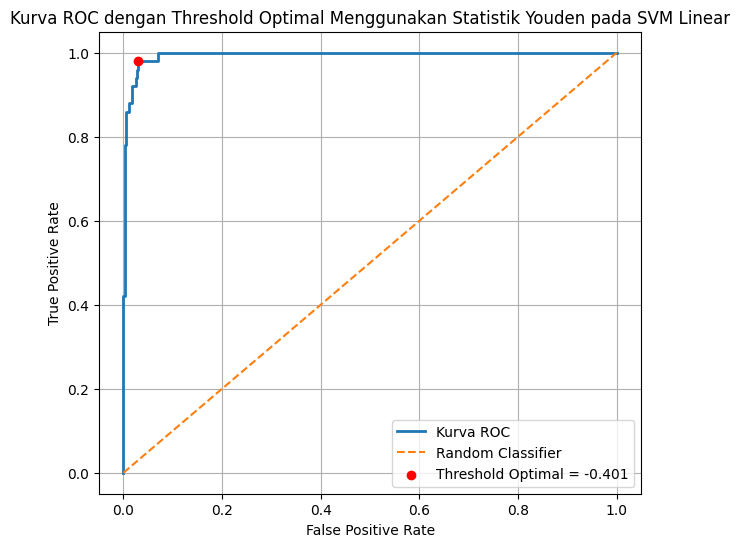

In [ ]:
# Kurva ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label='Kurva ROC', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.scatter(
    fpr[optimal_idx],
    tpr[optimal_idx],
    color='red',
    zorder=5,
    label=f'Threshold Optimal = {decision_train:.3f}'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC dengan Threshold Optimal Menggunakan Statistik Youden pada SVM Linear')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

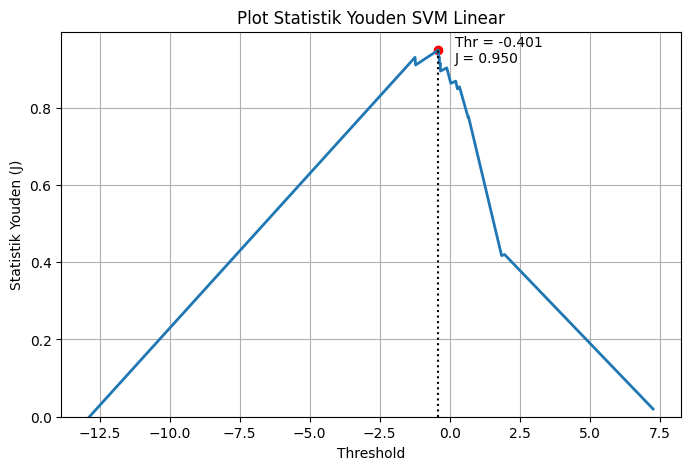

In [ ]:
# ============================
# Kurva Youden Index (Line Plot)
# ============================

# Buang threshold infinity
mask = np.isfinite(thresholds)
thresholds_clean = thresholds[mask]
youden_clean = youden_j_train[mask]

plt.figure(figsize=(8,5))

# Line plot Youden J
plt.plot(thresholds_clean, youden_clean, linewidth=2)

# Titik optimal
y_opt = youden_j_train[optimal_idx]

plt.vlines(decision_train, ymin=0, ymax=y_opt, linestyles=':', color='black')
plt.scatter(decision_train, y_opt, color='red')

plt.text(decision_train + 0.6, y_opt,
         f"Thr = {decision_train:.3f}\nJ = {y_opt:.3f}",
         verticalalignment='center')

plt.ylim(bottom=0)
plt.xlabel("Threshold")
plt.ylabel("Statistik Youden (J)")
plt.title("Plot Statistik Youden SVM Linear")
plt.grid(True)
plt.show()

In [ ]:
# ROC & Youden
fpr, tpr, thresholds = roc_curve(y_train, decision_scores_train)
youden_j = tpr - fpr

rows = []

for thr, tpr_i, fpr_i, j in zip(thresholds, tpr, fpr, youden_j):
    # Prediksi berdasarkan threshold
    y_pred_thr = (decision_scores_train >= thr).astype(int)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred_thr).ravel()

    rows.append({
        'Threshold': thr,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn,
        'TPR': tpr_i,
        'FPR': fpr_i,
        'Youden_J': j
    })

youden_df = pd.DataFrame(rows)
youden_df.to_excel('youden_statistic_testing.xlsx', index=False)

#### Manual

In [ ]:
thresholds = sorted(np.unique(decision_scores_train), reverse=True)
thresholds = [np.inf] + thresholds
thresholds

[inf,
 np.float64(7.270858473013887),
 np.float64(6.831967552856031),
 np.float64(6.485499568416929),
 np.float64(5.918093003726317),
 np.float64(5.478400919533091),
 np.float64(4.982455971610221),
 np.float64(4.318747752373984),
 np.float64(4.282646728787992),
 np.float64(4.07372047583622),
 np.float64(4.020737547849931),
 np.float64(3.8492917136394036),
 np.float64(3.7919435677483504),
 np.float64(3.616290769077099),
 np.float64(3.5025604648306894),
 np.float64(3.469567712066495),
 np.float64(3.1324563860042405),
 np.float64(3.005378777495334),
 np.float64(2.9109244752216883),
 np.float64(2.7806714662039935),
 np.float64(2.2873229177581287),
 np.float64(1.9657552915022416),
 np.float64(1.8578472979144562),
 np.float64(1.8228343866887196),
 np.float64(1.6661421474853908),
 np.float64(1.6012656665990948),
 np.float64(1.5700864745603695),
 np.float64(1.5562132411057465),
 np.float64(1.4027434791358644),
 np.float64(1.3167054301209946),
 np.float64(1.296013737962384),
 np.float64(1.20640

In [ ]:
def confusion_manual(y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)

    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    return TP, FP, TN, FN

fpr = []
tpr = []

for t in thresholds:
    TP, FP, TN, FN = confusion_manual(y_test, decision_scores, t)

    tpr.append(TP / (TP + FN) if (TP + FN) > 0 else 0)
    fpr.append(FP / (FP + TN) if (FP + TN) > 0 else 0)

In [ ]:
fpr = np.array(fpr)
tpr = np.array(tpr)

fpr, tpr

(array([0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.011, 0.011, 0.011, 0.011, 0.022, 0.022,
        0.022, 0.022, 0.022, 0.022, 0.022, 0.022, 0.022, 0.044, 0.044,
        0.077, 0.077, 0.077, 0.077, 0.077, 0.099, 0.099, 0.099, 0.099,
        0.099, 0.099, 0.099, 0.099, 0.099, 0.11 , 0.11 , 0.11 , 0.11 ,
        0.11 , 0.11 , 0.11 , 0.11 , 0.11 , 0.11 , 0.11 , 0.11 , 0.121,
        0.121, 0.121, 0.132, 0.143, 0.154, 0.165, 0.165, 0.165, 0.165,
        0.165, 0.165, 0.165, 0.165, 0.165, 0.165, 0.165, 0.165, 0.165,
        0.176, 0.176, 0.176, 0.176, 0.176, 0.176, 0.198, 0.209, 0.209,
        0.209, 0.209, 0.209, 0.209, 0.209, 0.22 , 0.231, 0.242, 0.253,
      

In [ ]:
youden_j = tpr - fpr
youden_j

array([0.   , 0.   , 0.   , 0.083, 0.083, 0.083, 0.083, 0.083, 0.083,
       0.083, 0.083, 0.167, 0.167, 0.167, 0.167, 0.167, 0.167, 0.167,
       0.167, 0.167, 0.167, 0.167, 0.167, 0.25 , 0.333, 0.333, 0.333,
       0.333, 0.5  , 0.5  , 0.5  , 0.5  , 0.5  , 0.5  , 0.5  , 0.5  ,
       0.5  , 0.5  , 0.5  , 0.5  , 0.5  , 0.5  , 0.583, 0.583, 0.667,
       0.667, 0.667, 0.833, 0.906, 0.906, 0.906, 0.906, 0.978, 0.978,
       0.978, 0.978, 0.978, 0.978, 0.978, 0.978, 0.978, 0.956, 0.956,
       0.923, 0.923, 0.923, 0.923, 0.923, 0.901, 0.901, 0.901, 0.901,
       0.901, 0.901, 0.901, 0.901, 0.901, 0.89 , 0.89 , 0.89 , 0.89 ,
       0.89 , 0.89 , 0.89 , 0.89 , 0.89 , 0.89 , 0.89 , 0.89 , 0.879,
       0.879, 0.879, 0.868, 0.857, 0.846, 0.835, 0.835, 0.835, 0.835,
       0.835, 0.835, 0.835, 0.835, 0.835, 0.835, 0.835, 0.835, 0.835,
       0.824, 0.824, 0.824, 0.824, 0.824, 0.824, 0.802, 0.791, 0.791,
       0.791, 0.791, 0.791, 0.791, 0.791, 0.78 , 0.769, 0.758, 0.747,
       0.747, 0.747,

In [ ]:
best_idx = np.argmax(youden_j)
best_threshold = thresholds[best_idx]

print("Best threshold (Youden):", best_threshold)
print("Youden J:", youden_j[best_idx])


Best threshold (Youden): -0.10096878451557822
Youden J: 0.978021978021978


### Prediksi

In [ ]:
y_pred_train_default = svm.predict(X_train_scaled)
f1_default = f1_score(y_train, y_pred_train_default)

print(confusion_matrix(y_train, y_pred_train_default))
print("F1-score pada threshold default:", f1_default)

[[355   6]
 [  6  44]]
F1-score pada threshold default: 0.88


In [ ]:
y_pred_train_opt = (decision_scores_train >= decision_train).astype(int)
f1 = f1_score(y_train, y_pred_train_opt)

print(confusion_matrix(y_train, y_pred_train_opt))
print("F1-score pada threshold Youden:", f1)

[[350  11]
 [  1  49]]
F1-score pada threshold Youden: 0.8909090909090909


In [ ]:
y_pred_default = svm.predict(X_test_scaled)
f1_default = f1_score(y_test, y_pred_default)

print(confusion_matrix(y_test, y_pred_default))
print("F1-score pada threshold default:", f1_default)

[[90  1]
 [ 1 11]]
F1-score pada threshold default: 0.9166666666666666


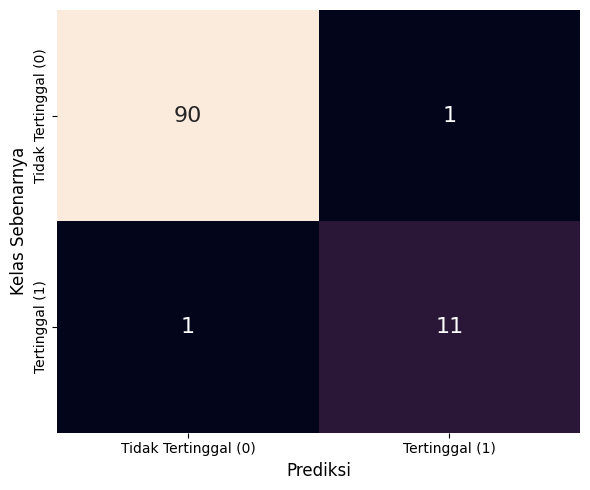

In [ ]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred_default)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, annot_kws={"size": 16},
            xticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'],
            yticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'])

plt.xlabel('Prediksi', fontsize=12)
plt.ylabel('Kelas Sebenarnya', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
y_pred_opt = (decision_scores >= decision_train).astype(int)
f1 = f1_score(y_test, y_pred_opt)

print(confusion_matrix(y_test, y_pred_opt))
print("F1-score pada threshold Youden:", f1)

[[89  2]
 [ 0 12]]
F1-score pada threshold Youden: 0.9230769230769231


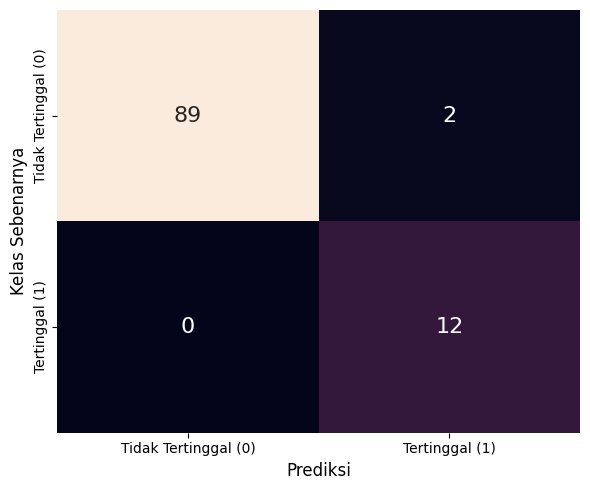

In [ ]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred_opt)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False,annot_kws={"size": 16},
            xticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'],
            yticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'])

plt.xlabel('Prediksi', fontsize=12)
plt.ylabel('Kelas Sebenarnya', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Dataframe
df_pred_test = pd.DataFrame({
    'No': range(1, len(y_test) + 1),
    'Prediksi_Default': y_pred_default,
    'Prediksi_Optimal': y_pred_opt,
    'Aktual': y_test.values
})

In [ ]:
def eval_components(y_true, y_pred, model_name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    f1 = f1_score(y_true, y_pred)

    return {
        'Model': model_name,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn,
        'F1_Score': round(f1, 4)
    }

eval_df = pd.DataFrame([
    eval_components(y_test, y_pred_default, 'Test - Default'),
    eval_components(y_test, y_pred_opt, 'Test - Youden')
])

In [ ]:
with pd.ExcelWriter('Hasil Prediksi SVM.xlsx', engine='openpyxl') as writer:
    df_pred_test.to_excel(
        writer, sheet_name='Prediksi Testing', index=False)
    eval_df.to_excel(
        writer, sheet_name='Evaluasi Model', index=False)

#### Prediksi Data Baru Manual

In [ ]:
data = X_test.iloc[0]
data

,511
P1,9.190
P2,4.260
GK,600536.000
PPK,5226.000
AHH,66.155
RLS,3.550
IKK,243.530
PKKP,14.720


In [ ]:
data_scaled = X_test_scaled.iloc[0]
data = data_scaled.values

In [ ]:
print(data_scaled)
print(data)

P1      4.758
P2      7.090
GK      0.331
PPK    -2.185
AHH    -1.268
RLS    -3.159
IKK     4.599
PKKP    0.400
Name: 511, dtype: float64
[ 4.758  7.09   0.331 -2.185 -1.268 -3.159  4.599  0.4  ]


In [ ]:
decision_manual = np.dot(w, data) + b
decision_manual
print("Nilai fungsi keputusan f(x):", decision_manual)

Nilai fungsi keputusan f(x): 5.354717815400493


In [ ]:
y_pred_manual = 1 if decision_manual > decision else 0
y_pred_manual

1

In [ ]:
decision_model = svm.decision_function(X_test_scaled.iloc[[0]])
decision_model

array([5.355])

In [ ]:
y_pred_model = svm.predict(X_test_scaled.iloc[[0]])
y_pred_model

print("Manual :", y_pred_manual)
print("Model  :", y_pred_model[0])

Manual : 1
Model  : 1


## RBF

In [ ]:
svm = SVC(
    kernel='rbf',
    C = 10,
    gamma = 0.1,
    probability=False,
    random_state=22020)

svm.fit(X_train_scaled, y_train)

SVC(C=10, gamma=0.1, random_state=22020)

In [ ]:
decision_scores_train = svm.decision_function(X_train_scaled)

In [ ]:
decision_scores_train

array([-1.989, -1.031, -2.018, -2.115, -1.586, -2.592,  1.   , -2.709,
       -1.88 , -1.824, -1.005, -1.   , -1.33 , -2.341, -1.467, -1.636,
       -1.987, -1.   , -2.539, -2.03 , -1.679, -2.323,  0.679, -2.239,
       -2.142, -2.254, -2.47 , -1.695, -2.669, -1.727, -1.332, -1.218,
       -0.716, -2.223, -2.285, -2.185, -1.244, -1.83 , -1.861, -1.794,
        1.   , -2.151,  1.   , -3.255, -1.301, -1.11 , -1.001, -1.8  ,
       -2.459,  1.556, -1.722,  0.369, -2.335,  1.   , -2.132, -1.446,
       -2.666, -2.513, -1.918, -1.   ,  1.07 , -2.779,  1.   , -2.48 ,
       -1.946, -2.369, -1.152, -2.313, -1.513, -1.887, -2.714, -1.   ,
       -1.926, -1.011, -1.044, -1.61 , -2.442, -1.773, -2.208, -2.74 ,
       -1.183, -2.196,  1.25 , -2.079, -1.757, -2.597, -1.82 , -2.436,
       -1.755, -2.697,  1.   , -2.433, -1.297,  1.129, -1.96 , -2.55 ,
       -1.789, -2.011, -1.613,  2.123,  2.072, -2.152, -0.36 ,  0.483,
       -0.722, -1.   ,  1.301, -1.971, -1.21 , -1.794, -1.818, -1.732,
      

In [ ]:
decision_scores = svm.decision_function(X_test_scaled)

In [ ]:
decision_scores

array([ 0.571, -1.534, -2.489, -1.837,  1.364, -2.143, -1.48 , -2.407,
       -2.285, -1.631, -1.8  , -2.54 , -1.933, -2.241, -1.692,  0.773,
       -1.798, -2.668,  1.159, -1.341, -0.444, -1.726, -1.149, -2.557,
       -1.627, -1.449, -0.712, -1.534,  1.532, -1.265,  0.724, -2.534,
       -2.306, -1.975, -2.31 ,  1.49 , -2.134, -1.55 , -2.057, -0.727,
       -1.088, -2.199, -2.206, -1.886, -1.769, -2.03 , -1.838, -1.581,
       -2.377, -2.323, -2.2  , -2.953, -1.493,  0.151, -1.681, -1.633,
       -0.852, -1.963, -1.466, -1.127, -2.072, -0.625, -1.202, -2.338,
        0.767, -1.752, -2.031, -1.445, -1.963, -1.651, -2.661, -1.786,
       -1.804, -2.984, -2.108, -2.278, -2.094, -1.635, -2.513,  0.456,
       -1.856,  0.042, -1.42 ,  0.375, -2.81 ,  0.642, -2.67 , -2.616,
       -1.805, -2.001, -2.221, -2.864, -2.322, -0.498, -2.105, -1.385,
       -1.328, -1.613,  0.651, -2.677, -2.133, -0.086, -2.006])

### Support Vector, Bobot, dan Bias

In [ ]:
print("Jumlah support vector per kelas:", svm.n_support_)
print("Total support vector:", svm.support_.shape[0])

Jumlah support vector per kelas: [29 29]
Total support vector: 58


In [ ]:
# support vector
SV = svm.support_vectors_

# alpha
alpha = np.abs(svm.dual_coef_[0])

# dual coef
aiyi = svm.dual_coef_[0]

# intercept
b = svm.intercept_[0]

In [ ]:
print(len(SV))
print(SV)

58
[[-0.699 -0.547  2.804  0.411  0.692  0.173 -0.005 -0.095]
 [-0.234 -0.371 -1.182 -1.033 -1.237 -0.397 -0.39   0.257]
 [ 0.842  0.735 -0.42  -0.67  -2.037 -0.605 -0.709 -0.517]
 [ 1.352  0.84  -0.481 -1.477 -0.769 -0.33  -0.676  0.229]
 [ 0.647  0.524 -1.157 -1.212 -0.536  0.46  -0.315 -0.277]
 [ 0.452  0.208  0.41  -0.064 -0.948  0.191 -0.16   2.421]
 [ 0.848  0.718  0.564 -0.943 -1.426 -0.189  0.618  1.214]
 [ 0.697  0.191 -0.546 -0.584 -0.48  -2.222 -0.24  -0.194]
 [-0.768 -0.669 -0.888 -1.136 -1.093 -0.176  0.012  1.93 ]
 [ 1.157  0.735  0.825 -0.863 -0.578 -0.36  -0.082  0.175]
 [-0.938 -0.74   1.012  3.754  1.132  1.55   0.268 -0.858]
 [-0.655 -0.617  2.445  2.341  0.494  2.689 -0.354 -0.504]
 [-0.932 -0.722  2.971  4.969  1.336  1.985  0.228 -0.982]
 [ 1.692  1.262 -0.252 -0.504 -1.212 -0.256 -0.619  0.178]
 [-0.718 -0.617  0.299  1.988  2.267  1.697 -0.026 -0.803]
 [ 2.811  2.93   0.952 -0.296 -0.459  1.128  0.762  2.362]
 [ 0.565  2.122 -0.244  0.073  0.045  0.068 -0.44  -0

In [ ]:
for i, pos in enumerate(svm.support_):
    print(f"data ke-{pos + 1} -> alpha = {alpha[i]:.3f}")

data ke-12 -> alpha = 0.258
data ke-18 -> alpha = 3.092
data ke-33 -> alpha = 10.000
data ke-52 -> alpha = 10.000
data ke-60 -> alpha = 0.298
data ke-72 -> alpha = 0.329
data ke-105 -> alpha = 10.000
data ke-106 -> alpha = 3.528
data ke-154 -> alpha = 6.657
data ke-163 -> alpha = 8.856
data ke-164 -> alpha = 0.009
data ke-172 -> alpha = 0.362
data ke-174 -> alpha = 1.198
data ke-208 -> alpha = 10.000
data ke-251 -> alpha = 0.255
data ke-261 -> alpha = 3.984
data ke-269 -> alpha = 0.221
data ke-272 -> alpha = 7.044
data ke-292 -> alpha = 0.590
data ke-304 -> alpha = 2.240
data ke-331 -> alpha = 9.235
data ke-334 -> alpha = 4.071
data ke-350 -> alpha = 0.249
data ke-355 -> alpha = 10.000
data ke-374 -> alpha = 7.025
data ke-383 -> alpha = 8.369
data ke-385 -> alpha = 3.716
data ke-409 -> alpha = 0.303
data ke-410 -> alpha = 4.074
data ke-7 -> alpha = 8.765
data ke-23 -> alpha = 10.000
data ke-41 -> alpha = 3.905
data ke-43 -> alpha = 4.926
data ke-54 -> alpha = 4.870
data ke-63 -> alpha 

In [ ]:
print(aiyi)

[ -0.258  -3.092 -10.    -10.     -0.298  -0.329 -10.     -3.528  -6.657
  -8.856  -0.009  -0.362  -1.198 -10.     -0.255  -3.984  -0.221  -7.044
  -0.59   -2.24   -9.235  -4.071  -0.249 -10.     -7.025  -8.369  -3.716
  -0.303  -4.074   8.765  10.      3.905   4.926   4.87    0.435   4.854
  10.     10.      0.409  10.      2.62    0.045   0.448   3.033   0.311
   0.27   10.      0.643   0.275  10.      4.661   4.994   3.317   0.522
  10.      3.474   2.677   0.509]


In [ ]:
print(len(alpha))
print(alpha)

58
[ 0.258  3.092 10.    10.     0.298  0.329 10.     3.528  6.657  8.856
  0.009  0.362  1.198 10.     0.255  3.984  0.221  7.044  0.59   2.24
  9.235  4.071  0.249 10.     7.025  8.369  3.716  0.303  4.074  8.765
 10.     3.905  4.926  4.87   0.435  4.854 10.    10.     0.409 10.
  2.62   0.045  0.448  3.033  0.311  0.27  10.     0.643  0.275 10.
  4.661  4.994  3.317  0.522 10.     3.474  2.677  0.509]


In [ ]:
print(b)

0.4830272444702296


#### Manual

In [ ]:
# support vector
sv = svm.support_vectors_

# aiyi
alpha_y = svm.dual_coef_[0]

# alpha
alpha = np.abs(svm.dual_coef_[0])

# yi support vector
y_sv = y_train.iloc[svm.support_].values

# c
c = svm.C

# gamma
gamma = svm.gamma

# sv untuk bias
sv_bias = sv[(alpha > 0) & (alpha < c)]

# alpha untuk sv bias
alpha_bias = alpha[(alpha > 0) & (alpha < c)]

# yi untuk sv bias
y_sv_bias = y_sv[(alpha > 0) & (alpha < c)]
y_sv_bias = np.where(y_sv_bias == 0, -1, 1)

In [ ]:
alpha_bias

array([0.258, 3.092, 0.298, 0.329, 3.528, 6.657, 8.856, 0.009, 0.362,
       1.198, 0.255, 3.984, 0.221, 7.044, 0.59 , 2.24 , 9.235, 4.071,
       0.249, 7.025, 8.369, 3.716, 0.303, 4.074, 8.765, 3.905, 4.926,
       4.87 , 0.435, 4.854, 0.409, 2.62 , 0.045, 0.448, 3.033, 0.311,
       0.27 , 0.643, 0.275, 4.661, 4.994, 3.317, 0.522, 3.474, 2.677,
       0.509])

In [ ]:
def rbf_kernel(x1, x2, gamma):
    return np.exp(-gamma * np.linalg.norm(x1 - x2) ** 2)

In [ ]:
bias_sv = []

for i in range(len(sv_bias)):
    xi = sv_bias[i]
    yi = y_sv_bias[i]

    kernel_sum = 0
    for j in range(len(sv)):
        kernel_sum += alpha_y[j] * rbf_kernel(sv[j], xi, gamma)

    b_i = yi - kernel_sum
    bias_sv.append(b_i)

    print(f"SV bias ke-{i+1}")
    print(f"bias_{i+1} = {b_i:.6f}")

SV bias ke-1
bias_1 = 0.483116
SV bias ke-2
bias_2 = 0.483481
SV bias ke-3
bias_3 = 0.482950
SV bias ke-4
bias_4 = 0.482666
SV bias ke-5
bias_5 = 0.482829
SV bias ke-6
bias_6 = 0.483010
SV bias ke-7
bias_7 = 0.482802
SV bias ke-8
bias_8 = 0.482663
SV bias ke-9
bias_9 = 0.482846
SV bias ke-10
bias_10 = 0.482846
SV bias ke-11
bias_11 = 0.482590
SV bias ke-12
bias_12 = 0.483141
SV bias ke-13
bias_13 = 0.483367
SV bias ke-14
bias_14 = 0.482953
SV bias ke-15
bias_15 = 0.483043
SV bias ke-16
bias_16 = 0.483096
SV bias ke-17
bias_17 = 0.482693
SV bias ke-18
bias_18 = 0.483468
SV bias ke-19
bias_19 = 0.482829
SV bias ke-20
bias_20 = 0.483064
SV bias ke-21
bias_21 = 0.483306
SV bias ke-22
bias_22 = 0.482767
SV bias ke-23
bias_23 = 0.483105
SV bias ke-24
bias_24 = 0.483364
SV bias ke-25
bias_25 = 0.482907
SV bias ke-26
bias_26 = 0.483009
SV bias ke-27
bias_27 = 0.483242
SV bias ke-28
bias_28 = 0.483326
SV bias ke-29
bias_29 = 0.483150
SV bias ke-30
bias_30 = 0.483387
SV bias ke-31
bias_31 = 0.48

In [ ]:
b_manual = np.mean(bias_sv)
b_manual

np.float64(0.48302724119079543)

### Optimasi Threshold

In [ ]:
# Youden Statistik
fpr, tpr, thresholds = roc_curve(y_train, decision_scores_train)
youden_j_train = tpr - fpr

optimal_idx = np.argmax(youden_j_train)
decision_train = thresholds[optimal_idx]

print("Best threshold (Youden):", decision_train)
print("Youden J:", youden_j_train[optimal_idx])

Best threshold (Youden): -0.46525131834017763
Youden J: 0.9744598337950139


In [ ]:
roc_curve(y_train, decision_scores_train)

(array([0.        , 0.        , 0.        , 0.00554017, 0.00554017,
        0.1634349 , 0.1634349 , 1.        ]),
 array([0.  , 0.02, 0.94, 0.94, 0.98, 0.98, 1.  , 1.  ]),
 array([        inf,  2.86306067,  0.48342189, -0.12414276, -0.46525132,
        -1.24394859, -1.25029009, -3.30126522]))

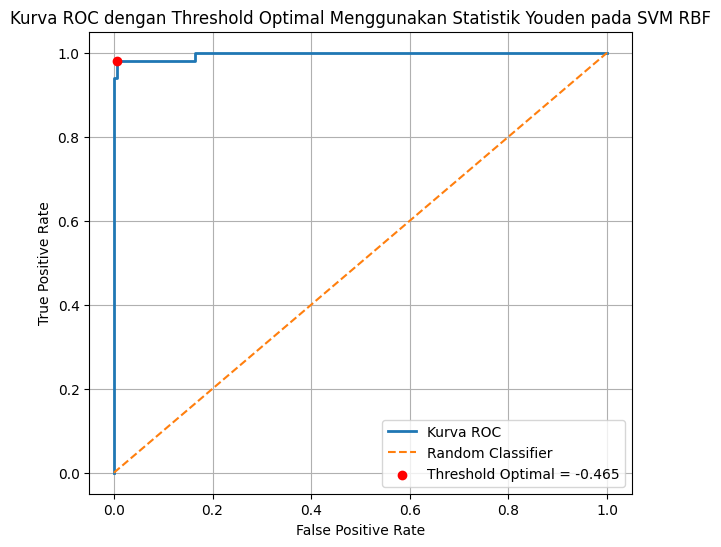

In [ ]:
# Kurva ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label='Kurva ROC', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.scatter(
    fpr[optimal_idx],
    tpr[optimal_idx],
    color='red',
    zorder=5,
    label=f'Threshold Optimal = {decision_train:.3f}'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC dengan Threshold Optimal Menggunakan Statistik Youden pada SVM RBF')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

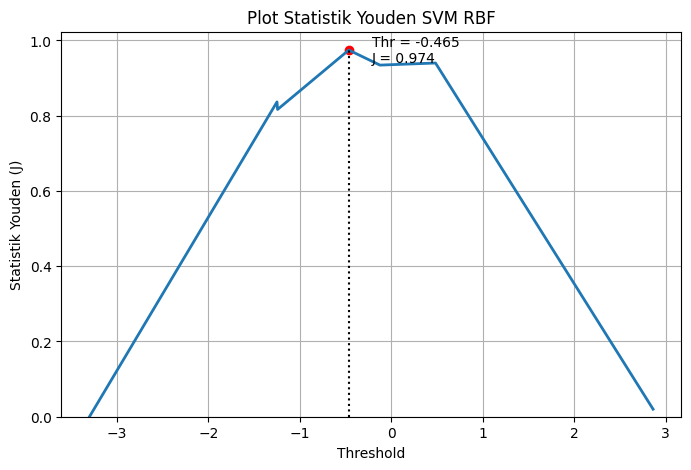

In [ ]:
# ============================
# Kurva Youden Index (Line Plot)
# ============================

# Buang threshold infinity
mask = np.isfinite(thresholds)
thresholds_clean = thresholds[mask]
youden_clean = youden_j_train[mask]

plt.figure(figsize=(8,5))

# Line plot Youden J
plt.plot(thresholds_clean, youden_clean, linewidth=2)

# Titik optimal
y_opt = youden_j_train[optimal_idx]

plt.vlines(decision_train, ymin=0, ymax=y_opt, linestyles=':', color='black')
plt.scatter(decision_train, y_opt, color='red')

plt.text(decision_train + 0.25, y_opt,
         f"Thr = {decision_train:.3f}\nJ = {y_opt:.3f}",
         verticalalignment='center')

plt.ylim(bottom=0)
plt.xlabel("Threshold")
plt.ylabel("Statistik Youden (J)")
plt.title("Plot Statistik Youden SVM RBF")
plt.grid(True)
plt.show()

In [ ]:
# ROC & Youden
fpr, tpr, thresholds = roc_curve(y_train, decision_scores_train)
youden_j = tpr - fpr

rows = []

for thr, tpr_i, fpr_i, j in zip(thresholds, tpr, fpr, youden_j):
    # Prediksi berdasarkan threshold
    y_pred_thr = (decision_scores_train >= thr).astype(int)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred_thr).ravel()

    rows.append({
        'Threshold': thr,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn,
        'TPR': tpr_i,
        'FPR': fpr_i,
        'Youden_J': j
    })

youden_df = pd.DataFrame(rows)
youden_df.to_excel('Statistik Youden RBF.xlsx', index=False)

### Prediksi Data Baru Manual

In [ ]:
x_new = X_train_scaled.iloc[0].values


In [ ]:
def rbf_kernel(x1, x2, gamma):
    return np.exp(-gamma * np.linalg.norm(x1 - x2)**2)

In [ ]:
decision_value = 0

for j in range(len(sv)):
    K = rbf_kernel(x_new, sv[j], gamma)
    decision_value += alpha_y[j] * K

decision_value += b

decision_value

2.7806944935140394e-10
-1.989235881570377


In [ ]:
decision_value - b

np.float64(-2.4722631260406067)

In [ ]:
y_pred_manual = 1 if decision_value >= 0 else -1

print("Decision value f(x):", decision_value)
print("Prediksi kelas manual:", y_pred_manual)

Decision value f(x): -1.989235881570377
Prediksi kelas manual: -1


In [ ]:
decision_model = svm.decision_function(x_new.reshape(1, -1))[0]

print("Decision score dari model:", decision_model)
print("Prediksi model SVM:", svm.predict(x_new.reshape(1, -1))[0])

Decision score dari model: -1.989235881570374
Prediksi model SVM: 0


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


### Prediksi

In [ ]:
y_pred_train_default = svm.predict(X_train_scaled)
f1_default = f1_score(y_train, y_pred_train_default)

print(confusion_matrix(y_train, y_pred_train_default))
print("F1-score pada threshold default:", f1_default)

[[360   1]
 [  3  47]]
F1-score pada threshold default: 0.9591836734693877


In [ ]:
y_pred_train_opt = (decision_scores_train >= decision_train).astype(int)
f1 = f1_score(y_train, y_pred_train_opt)

print(confusion_matrix(y_train, y_pred_train_opt))
print("F1-score pada threshold Youden:", f1)

[[359   2]
 [  1  49]]
F1-score pada threshold Youden: 0.9702970297029703


In [ ]:
y_pred_default = svm.predict(X_test_scaled)
f1_default = f1_score(y_test, y_pred_default)

print(confusion_matrix(y_test, y_pred_default))
print("F1-score pada threshold default:", f1_default)

[[88  3]
 [ 1 11]]
F1-score pada threshold default: 0.8461538461538461


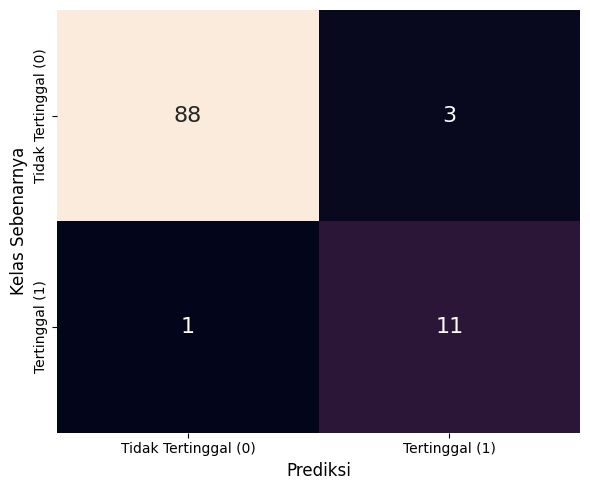

In [ ]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred_default)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False,annot_kws={"size": 16},
            xticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'],
            yticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'])

plt.xlabel('Prediksi', fontsize=12)
plt.ylabel('Kelas Sebenarnya', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
y_pred_opt = (decision_scores >= decision_train).astype(int)
f1 = f1_score(y_test, y_pred_opt)

print(confusion_matrix(y_test, y_pred_opt))
print("F1-score pada threshold Youden:", f1)

[[87  4]
 [ 0 12]]
F1-score pada threshold Youden: 0.8571428571428571


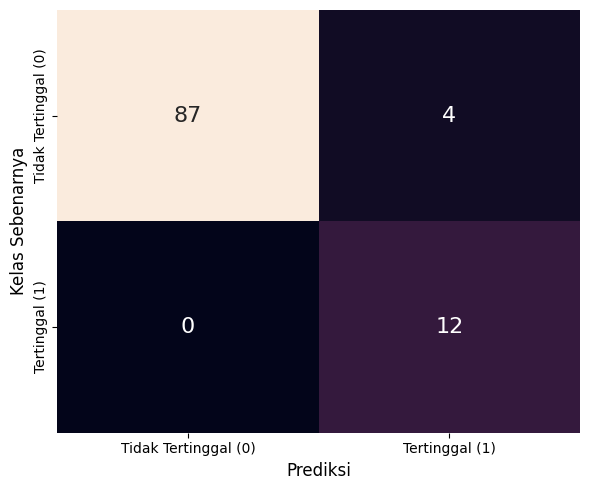

In [ ]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred_opt)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, annot_kws={"size": 16},
            xticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'],
            yticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'])

plt.xlabel('Prediksi', fontsize=12)
plt.ylabel('Kelas Sebenarnya', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Dataframe
df_pred_test = pd.DataFrame({
    'No': range(1, len(y_test) + 1),
    'Prediksi_Default': y_pred_default,
    'Prediksi_Optimal': y_pred_opt,
    'Aktual': y_test.values
})

In [ ]:
def eval_components(y_true, y_pred, model_name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    f1 = f1_score(y_true, y_pred)

    return {
        'Model': model_name,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn,
        'F1_Score': round(f1, 4)
    }

eval_df = pd.DataFrame([
    eval_components(y_test, y_pred_default, 'Default'),
    eval_components(y_test, y_pred_opt, 'Optimal')
])

In [ ]:
with pd.ExcelWriter('Hasil Prediksi SVM RBF.xlsx', engine='openpyxl') as writer:
    df_pred_test.to_excel(
        writer, sheet_name='Prediksi Testing', index=False)
    eval_df.to_excel(
        writer, sheet_name='Evaluasi Model', index=False)